# AI-Powered Solar Energy Generation Forecasting
## Using Weather-Aware Machine Learning Models  (DKASC Alice Springs, site 31, ~12 years of real data)

## Introduction

**Goal:** forecast the plant's AC power **1 hour ahead** using only information available at forecast time.

**Dataset:** DKASC (Desert Knowledge Australia Solar Centre) system "DKA M18 C-Phase, site 31", 5-minute data.
Power is zero in 2010-2012, so the analysis starts when real output begins (2013-08).

**Key design choices (all leakage-safe):**
- Hourly values are averaged over the hour **ending** at the forecast time, so nothing from the future is used.
- Power is divided by a *trailing* capacity estimate (past data only) because the system's output slowly degrades over the years.
- Chronological 60/20/20 train/validation/test split with a purge gap. Early stopping and model selection use validation only.
- Rows built on filled-in gaps (missing sensor data) are excluded from training, validation and testing.
- Naive baselines (persistence, same-hour-yesterday) are reported next to every model.

## Dataset Loading & Understanding

In [3]:
import warnings
warnings.filterwarnings('ignore')

import os
import csv
import time
import zipfile

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import xgboost as xgb
import lightgbm as lgb

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import shap

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': '#f8f9fa', 'axes.grid': True,
                     'grid.alpha': 0.4, 'axes.titlesize': 14, 'axes.labelsize': 12})
PALETTE = ['#2196F3', '#FF9800', '#4CAF50', '#F44336', '#9C27B0', '#00BCD4']

# ── Configuration ───────────────────────────────────────────────────────────
STEP_MIN    = 60            # model time step in minutes (60 = hourly; 15 also works but is much slower)
S           = 60 // STEP_MIN    # steps per hour
H           = S             # forecast horizon in steps  -> 1 hour ahead
DATA_FILE   = "74-Site_DKA-M18_C-Phase-site31.csv"   # (or put archive.zip containing it next to this script)
FIRST_VALID = "2013-08-01"  # power is all zeros before this date (system not reporting)
NIGHT_EPS   = 0.01          # predictions below 1% of capacity are set to 0 (no sun -> no power)

print("All libraries loaded successfully!")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | XGBoost {xgb.__version__} | "
      f"LightGBM {lgb.__version__} | TensorFlow {tf.__version__}")

# Look for the data next to this script, in the working folder, or in Colab's /content
_here = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()

def find_data():
    for d in [_here, os.getcwd(), "/content", "/mnt/user-data/uploads", "/tmp/dk"]:
        for name in [DATA_FILE, "archive.zip"]:
            p = os.path.join(d, name)
            if os.path.isfile(p):
                return p
    raise FileNotFoundError(f"Could not find {DATA_FILE} (or archive.zip). Put it next to this script/notebook and run again. "
                            "No fake data is generated.")

DATA_PATH = find_data()
print("\nUsing data file:", DATA_PATH)

# The file's last row is cut off in some copies, so quoting is disabled (the timestamp quotes are stripped by hand).
want = ["timestamp", "Active_Power", "Weather_Temperature_Celsius", "Weather_Relative_Humidity",
        "Global_Horizontal_Radiation", "Diffuse_Horizontal_Radiation"]   # wind speed is empty after 2016, so it is not used
src = DATA_PATH
if DATA_PATH.endswith(".zip"):
    zf = zipfile.ZipFile(DATA_PATH)
    src = zf.open([n for n in zf.namelist() if n.lower().endswith(".csv")][0])
raw = pd.read_csv(src, usecols=lambda c: c in want, quoting=csv.QUOTE_NONE)

raw["timestamp"] = pd.to_datetime(raw["timestamp"].astype(str).str.strip('"'), errors="coerce")
n_raw = len(raw)
raw = raw.dropna(subset=["timestamp"])
n_bad_ts = n_raw - len(raw)
for c in want[1:]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
raw = raw.sort_values("timestamp")
n_dup = int(raw["timestamp"].duplicated().sum())
raw = raw.drop_duplicates("timestamp", keep="first").set_index("timestamp")

raw = raw.rename(columns={"Active_Power": "AC_POWER", "Weather_Temperature_Celsius": "AMBIENT_TEMPERATURE",
                          "Weather_Relative_Humidity": "HUMIDITY", "Global_Horizontal_Radiation": "IRRADIATION",
                          "Diffuse_Horizontal_Radiation": "DIFFUSE"})
raw["IRRADIATION"] = raw["IRRADIATION"] / 1000.0      # W/m2 -> kW/m2
raw["DIFFUSE"] = raw["DIFFUSE"] / 1000.0
n_neg = int((raw["AC_POWER"] < 0).sum())
raw["AC_POWER"] = raw["AC_POWER"].clip(lower=0)        # tiny negative night readings -> 0
raw_full = raw.copy()                                  # kept for the data-quality plots below
raw = raw.loc[FIRST_VALID:]

print(f"\nRaw 5-min rows read          : {n_raw:,}  (unparseable/truncated rows dropped: {n_bad_ts})")
print(f"Duplicate timestamps removed : {n_dup}")
print(f"Negative power readings -> 0 : {n_neg}")
print(f"Analysis period              : {raw.index.min()} to {raw.index.max()}  ({len(raw):,} 5-min rows)")

# ── Hourly series: mean over the hour ENDING at the label (so nothing from the future is used) ──
rs = raw.resample(f"{STEP_MIN}min", closed="right", label="right")
df = rs.mean().where(rs.count() >= 0.66 * STEP_MIN / 5)      # need >= 66% of the 5-min samples in the hour
df = df.interpolate(method="time", limit=2 * S, limit_area="inside")   # fill only gaps up to 2 hours

core = ["AC_POWER", "IRRADIATION", "DIFFUSE", "AMBIENT_TEMPERATURE", "HUMIDITY"]
# rows still empty = real gaps longer than 2 hours: filled later to keep the grid regular, but FLAGGED
df["LONG_GAP"] = df[core].isna().any(axis=1)

# Trailing capacity estimate (kW): 90th percentile of the last 365 daily peaks, shifted one day so only PAST data is used.
daily_peak = df["AC_POWER"].resample("D").max()
cap_daily = daily_peak.rolling(365, min_periods=180).quantile(0.90).shift(1)
df["CAP"] = cap_daily.reindex(df.index.normalize()).values
df = df[df["CAP"].notna()]                      # first ~6 months have no capacity estimate yet
df[core] = df[core].ffill().bfill()
df = df.reset_index().rename(columns={"timestamp": "DATE_TIME"})

print(f"\nHourly rows                  : {len(df):,}")
print(f"Date range                   : {df['DATE_TIME'].min()} to {df['DATE_TIME'].max()}")
print(f"Rows flagged as long gaps    : {int(df['LONG_GAP'].sum()):,} ({df['LONG_GAP'].mean()*100:.1f}%)")
print(f"Capacity estimate (kW)       : {df['CAP'].iloc[0]:.2f} (start)  ->  {df['CAP'].iloc[-1]:.2f} (end)")
print(df.head().to_string())

All libraries loaded successfully!
NumPy 2.1.3 | Pandas 2.2.3 | XGBoost 3.4.1 | LightGBM 4.6.0 | TensorFlow 2.21.0

Using data file: /content/74-Site_DKA-M18_C-Phase-site31.csv

Raw 5-min rows read          : 1,621,108  (unparseable/truncated rows dropped: 2)
Duplicate timestamps removed : 67
Negative power readings -> 0 : 106
Analysis period              : 2013-08-01 00:00:00 to 2025-09-04 12:00:00  (1,258,600 5-min rows)

Hourly rows                  : 101,557
Date range                   : 2014-02-03 00:00:00 to 2025-09-04 12:00:00
Rows flagged as long gaps    : 3,449 (3.4%)
Capacity estimate (kW)       : 4.17 (start)  ->  2.99 (end)
            DATE_TIME  AC_POWER  AMBIENT_TEMPERATURE   HUMIDITY  IRRADIATION   DIFFUSE  LONG_GAP       CAP
0 2014-02-03 00:00:00      0.01            28.217077  44.433551     0.002658  0.001216     False  4.166603
1 2014-02-03 01:00:00      0.01            27.075559  48.182135     0.002378  0.001072     False  4.166603
2 2014-02-03 02:00:00      0.01   

### Data Quality Overview

             rows  power_available_%  peak_power_kW  weather_available_%
timestamp                                                               
2010        91121               98.0           0.00                100.0
2011       104903               97.0           0.00                 99.0
2012       105396               96.0           0.01                100.0
2013       105077               96.0           4.87                100.0
2014       105111              100.0           5.10                100.0
2015       105120              100.0           4.97                100.0
2016       105408              100.0           5.01                100.0
2017       105077               98.0           4.97                 99.0
2018       105120               92.0           4.64                100.0
2019       102905               99.0           4.48                100.0
2020       105382               98.0           4.07                100.0
2021       100539               99.0           3.88

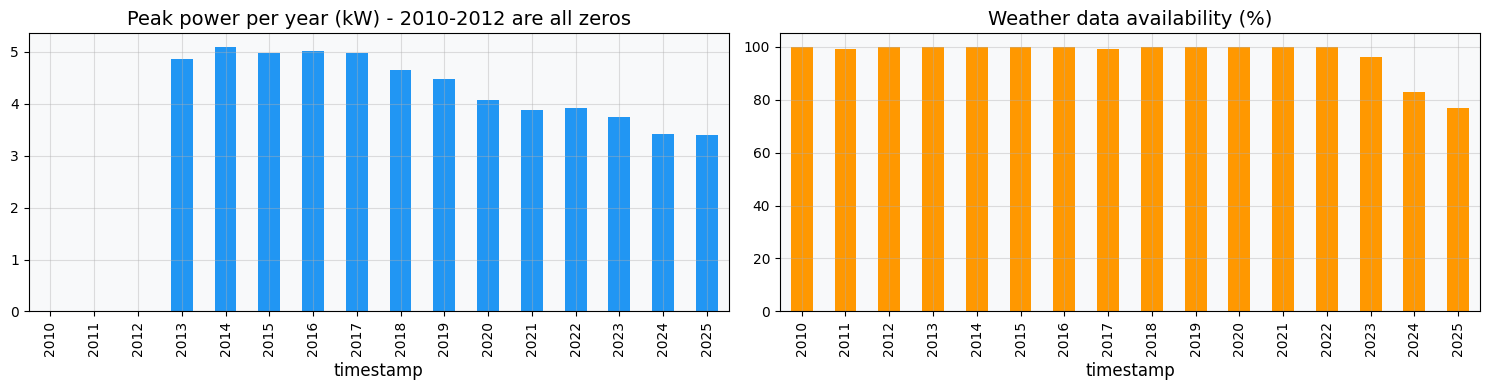

In [4]:
yr = raw_full.groupby(raw_full.index.year)
qual = pd.DataFrame({
    'rows': yr.size(),
    'power_available_%': yr['AC_POWER'].apply(lambda x: x.notna().mean() * 100).round(0),
    'peak_power_kW': yr['AC_POWER'].max().round(2),
    'weather_available_%': yr['IRRADIATION'].apply(lambda x: x.notna().mean() * 100).round(0)})
print(qual.to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
qual['peak_power_kW'].plot(kind='bar', ax=ax[0], color='#2196F3'); ax[0].set_title("Peak power per year (kW) - 2010-2012 are all zeros")
qual['weather_available_%'].plot(kind='bar', ax=ax[1], color='#FF9800'); ax[1].set_title("Weather data availability (%)")
plt.tight_layout(); plt.savefig('data_quality.png', dpi=150, bbox_inches='tight'); plt.show()

## Data Preprocessing

In [5]:
print("Preprocessing steps already applied while loading:")
print(f"  - truncated/unparseable rows dropped : {n_bad_ts}")
print(f"  - duplicate timestamps removed       : {n_dup}")
print(f"  - negative power clipped to 0        : {n_neg}")
print(f"  - early all-zero years removed       : data starts {FIRST_VALID}")
print("  - hourly means over the hour ending at the label; gaps <= 2 h interpolated, longer gaps flagged (LONG_GAP)")
print("  - trailing capacity (CAP) estimated from past data only")
print(f"\nMissing values now: {int(df[core].isna().sum().sum())}")

Preprocessing steps already applied while loading:
  - truncated/unparseable rows dropped : 2
  - duplicate timestamps removed       : 67
  - negative power clipped to 0        : 106
  - early all-zero years removed       : data starts 2013-08-01
  - hourly means over the hour ending at the label; gaps <= 2 h interpolated, longer gaps flagged (LONG_GAP)
  - trailing capacity (CAP) estimated from past data only

Missing values now: 0


### Distribution of Key Variables

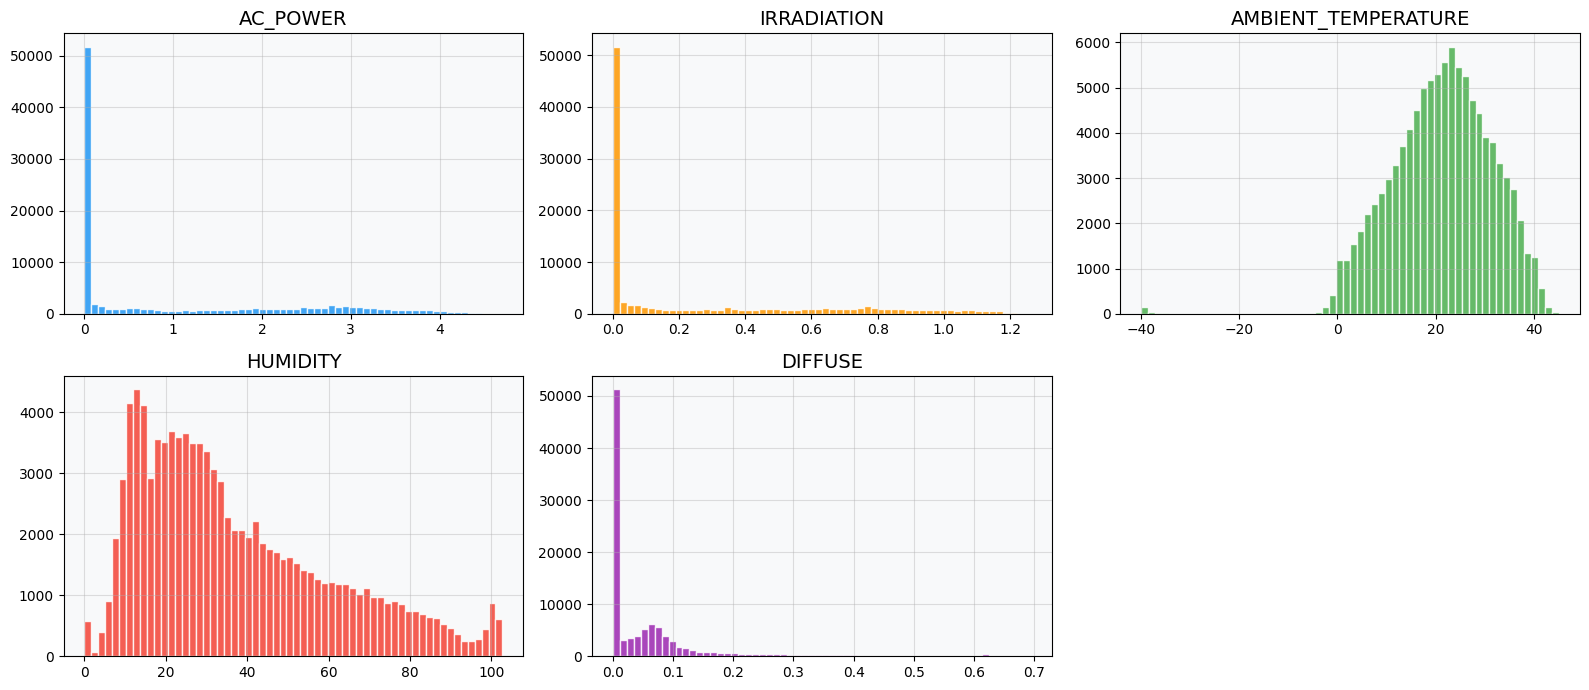

In [6]:
vars_ = ['AC_POWER', 'IRRADIATION', 'AMBIENT_TEMPERATURE', 'HUMIDITY', 'DIFFUSE']
fig, axes = plt.subplots(2, 3, figsize=(16, 7)); axes.ravel()[-1].axis('off')
for ax, v, c in zip(axes.ravel(), vars_, PALETTE):
    ax.hist(df[v], bins=60, color=c, alpha=0.85, edgecolor='white'); ax.set_title(v)
plt.tight_layout(); plt.savefig('distributions.png', dpi=150, bbox_inches='tight'); plt.show()

### Daily Pattern, Seasonality and Output Drift

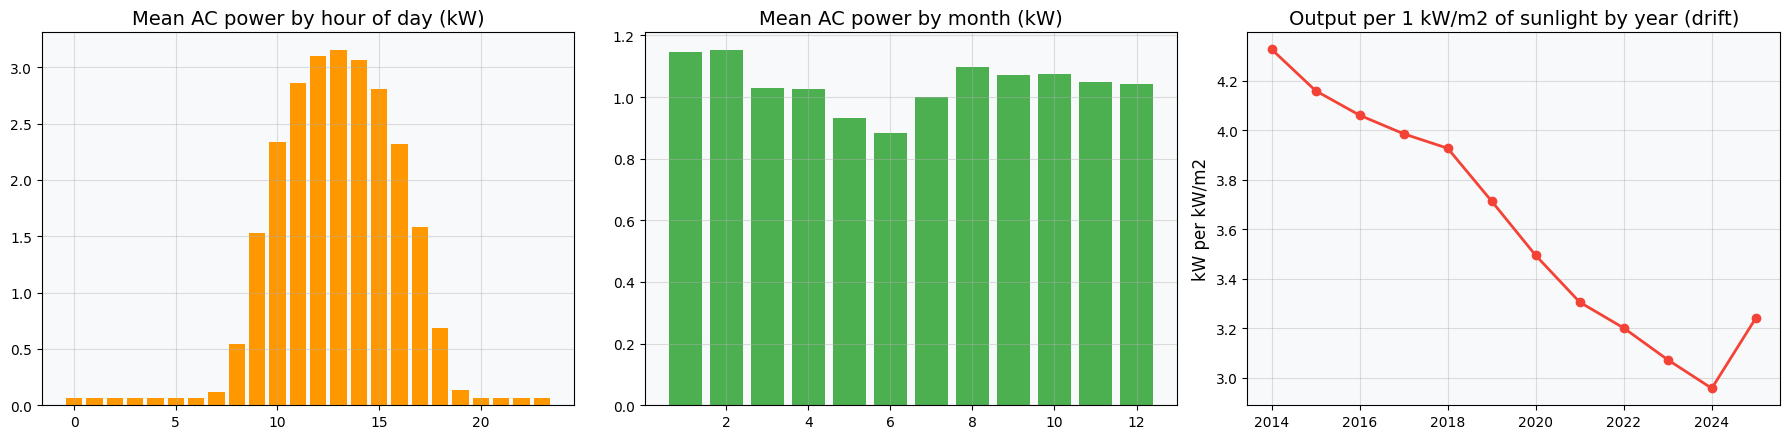

Output per unit sunlight fell from 4.33 to 3.24 kW per kW/m2 (-25%) -> power is divided by a trailing capacity estimate.


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
hourly = df.groupby(df['DATE_TIME'].dt.hour)['AC_POWER'].mean()
axes[0].bar(hourly.index, hourly.values, color='#FF9800'); axes[0].set_title("Mean AC power by hour of day (kW)")
monthly = df.groupby(df['DATE_TIME'].dt.month)['AC_POWER'].mean()
axes[1].bar(monthly.index, monthly.values, color='#4CAF50'); axes[1].set_title("Mean AC power by month (kW)")
sun = df[(df['IRRADIATION'] > 0.6) & (~df['LONG_GAP'])]
ratio = (sun['AC_POWER'] / sun['IRRADIATION']).groupby(sun['DATE_TIME'].dt.year).median()
axes[2].plot(ratio.index, ratio.values, 'o-', color='#F44336', lw=2)
axes[2].set_title("Output per 1 kW/m2 of sunlight by year (drift)"); axes[2].set_ylabel("kW per kW/m2")
plt.tight_layout(); plt.savefig('patterns_and_drift.png', dpi=150, bbox_inches='tight'); plt.show()
print(f"Output per unit sunlight fell from {ratio.iloc[0]:.2f} to {ratio.iloc[-1]:.2f} kW per kW/m2 "
      f"({(ratio.iloc[-1] / ratio.iloc[0] - 1) * 100:.0f}%) -> power is divided by a trailing capacity estimate.")

### Correlation

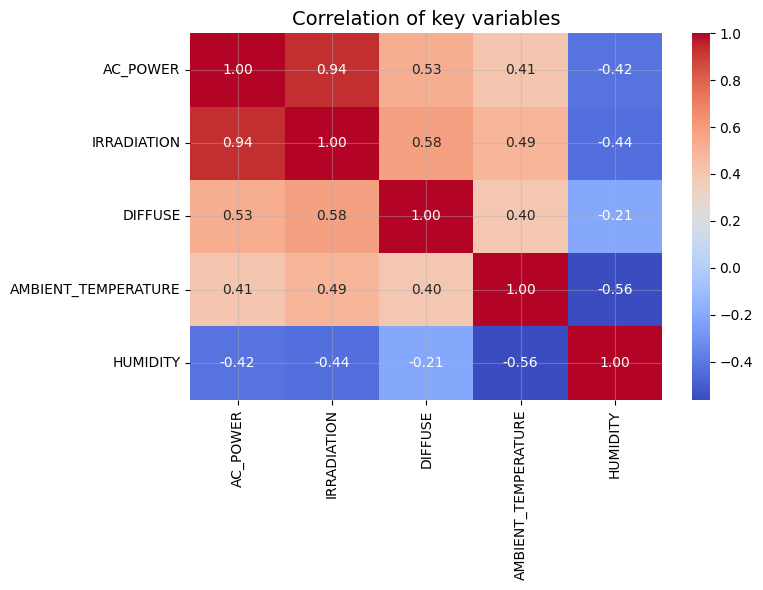

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[core].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title("Correlation of key variables"); plt.tight_layout()
plt.savefig('correlation.png', dpi=150, bbox_inches='tight'); plt.show()

## Feature Engineering

In [10]:
TARGET = 'TARGET_REL'      # AC power H steps ahead, as a fraction of the trailing capacity

def make_features(d, H=H):
    """
    Features known at the moment the forecast is ISSUED (time t), used to predict AC power at t+H.
    Nothing from after t is used. The streaming section reuses this exact function.
    Power features are relative to the trailing capacity (CAP) so that slow output degradation does not
    create a train/test mismatch.
    """
    f = d.copy()
    f['AC_REL'] = f['AC_POWER'] / f['CAP']
    f['AC_NOW'] = f['AC_POWER']                       # kW, used by the persistence baseline only

    tt = pd.to_datetime(f['DATE_TIME']) + pd.Timedelta(minutes=STEP_MIN * H)   # the moment being predicted
    hr = tt.dt.hour + tt.dt.minute / 60
    doy = tt.dt.dayofyear
    f['HOUR_SIN'] = np.sin(2 * np.pi * hr / 24);  f['HOUR_COS'] = np.cos(2 * np.pi * hr / 24)
    f['DOY_SIN'] = np.sin(2 * np.pi * doy / 365.25); f['DOY_COS'] = np.cos(2 * np.pi * doy / 365.25)

    for hrs in [1, 2, 3, 6, 12, 24]:
        f[f'LAG_{hrs}H'] = f['AC_REL'].shift(hrs * S)
    f['AC_SAME_TIME_YDAY_REL'] = f['AC_REL'].shift(24 * S - H)
    f['AC_SAME_TIME_YDAY'] = f['AC_POWER'].shift(24 * S - H)      # kW, baseline only

    for hrs in [1, 3]:
        f[f'IRR_LAG_{hrs}H'] = f['IRRADIATION'].shift(hrs * S)
    f['IRR_CHANGE_1H'] = f['IRRADIATION'] - f['IRRADIATION'].shift(S)
    f['DIFFUSE_FRAC'] = (f['DIFFUSE'] / f['IRRADIATION'].clip(lower=0.02)).clip(0, 1.5)   # cloudiness signal

    for w in [3, 6, 24]:
        f[f'ROLL_MEAN_{w}H'] = f['AC_REL'].rolling(w * S, min_periods=1).mean()
        f[f'ROLL_STD_{w}H'] = f['AC_REL'].rolling(w * S, min_periods=1).std().fillna(0)
    return f

feat_cols = ['AC_REL', 'HOUR_SIN', 'HOUR_COS', 'DOY_SIN', 'DOY_COS',
             'IRRADIATION', 'DIFFUSE_FRAC', 'AMBIENT_TEMPERATURE', 'HUMIDITY',
             'LAG_1H', 'LAG_2H', 'LAG_3H', 'LAG_6H', 'LAG_12H', 'LAG_24H', 'AC_SAME_TIME_YDAY_REL',
             'IRR_LAG_1H', 'IRR_LAG_3H', 'IRR_CHANGE_1H',
             'ROLL_MEAN_3H', 'ROLL_STD_3H', 'ROLL_MEAN_6H', 'ROLL_STD_6H', 'ROLL_MEAN_24H', 'ROLL_STD_24H']

df_fe = make_features(df)
df_fe['TARGET_TIME'] = df_fe['DATE_TIME'] + pd.Timedelta(minutes=STEP_MIN * H)
df_fe[TARGET] = df_fe['AC_REL'].shift(-H)                  # what we predict (relative)
df_fe['TARGET_KW'] = df_fe['AC_POWER'].shift(-H)           # the same target in kW (used for evaluation)
df_fe['TARGET_GAP'] = df_fe['LONG_GAP'].astype(float).shift(-H)
# a row is "contaminated" if a filled-in gap row lies within the 24 h look-back or is the target itself
df_fe['GAP_NEAR'] = df_fe['LONG_GAP'].astype(int).rolling(24 * S + 1, min_periods=1).max()

df_fe = df_fe.dropna(subset=feat_cols + [TARGET, 'TARGET_KW', 'TARGET_GAP']).reset_index(drop=True)
assert (df_fe['DATE_TIME'].diff().dropna() == pd.Timedelta(minutes=STEP_MIN)).all(), "time grid must be regular"
bad_row = ((df_fe['GAP_NEAR'] > 0) | (df_fe['TARGET_GAP'] > 0)).values

print(f"Forecast horizon : {H} step(s) = {STEP_MIN * H} minutes ahead")
print(f"Rows after feature engineering: {len(df_fe):,} | features: {len(feat_cols)}")
print(feat_cols)

Forecast horizon : 1 step(s) = 60 minutes ahead
Rows after feature engineering: 101,532 | features: 25
['AC_REL', 'HOUR_SIN', 'HOUR_COS', 'DOY_SIN', 'DOY_COS', 'IRRADIATION', 'DIFFUSE_FRAC', 'AMBIENT_TEMPERATURE', 'HUMIDITY', 'LAG_1H', 'LAG_2H', 'LAG_3H', 'LAG_6H', 'LAG_12H', 'LAG_24H', 'AC_SAME_TIME_YDAY_REL', 'IRR_LAG_1H', 'IRR_LAG_3H', 'IRR_CHANGE_1H', 'ROLL_MEAN_3H', 'ROLL_STD_3H', 'ROLL_MEAN_6H', 'ROLL_STD_6H', 'ROLL_MEAN_24H', 'ROLL_STD_24H']


### Correlation with the target

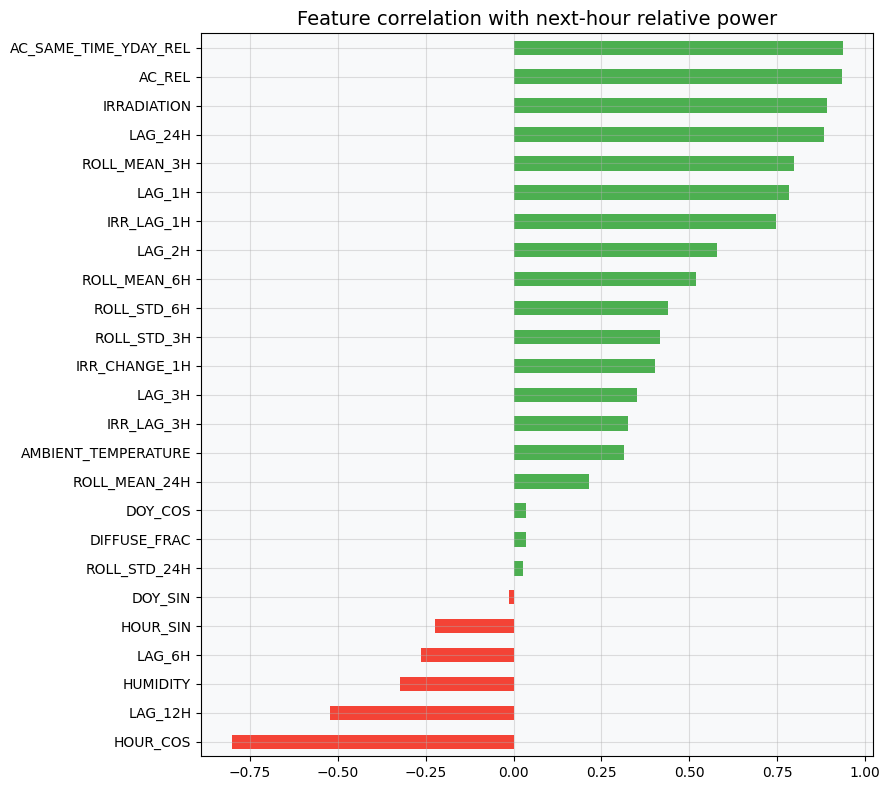

In [11]:
corr = df_fe[feat_cols + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
corr.plot(kind='barh', ax=ax, color=['#F44336' if v < 0 else '#4CAF50' for v in corr])
ax.set_title("Feature correlation with next-hour relative power"); plt.tight_layout()
plt.savefig('feature_correlation.png', dpi=150, bbox_inches='tight'); plt.show()

## Model Development

In [12]:
n = len(df_fe)
a, b = int(n * 0.60), int(n * 0.80)          # 60% train | 20% validation | 20% test, in time order
GAP = H                                      # skip H rows between splits so targets never overlap

train_idx = np.arange(0, a)[~bad_row[:a]]
val_idx = np.arange(a + GAP, b)[~bad_row[a + GAP:b]]
test_idx = np.arange(b + GAP, n)[~bad_row[b + GAP:]]
print(f"Rows excluded for gap contamination -> train: {a - len(train_idx)}, "
      f"validation: {(b - a - GAP) - len(val_idx)}, test: {(n - b - GAP) - len(test_idx)}")

train_df, val_df, test_df = df_fe.iloc[train_idx], df_fe.iloc[val_idx], df_fe.iloc[test_idx]
X_train, X_val, X_test = (x[feat_cols].values for x in (train_df, val_df, test_df))
y_train_rel, y_val_rel, y_test_rel = (x[TARGET].values for x in (train_df, val_df, test_df))
y_train, y_val, y_test = (x['TARGET_KW'].values for x in (train_df, val_df, test_df))     # kW
cap_train, cap_val, cap_test = (x['CAP'].values for x in (train_df, val_df, test_df))

print(f"Train : {len(X_train):,}  ({train_df['DATE_TIME'].min().date()} -> {train_df['DATE_TIME'].max().date()})")
print(f"Val   : {len(X_val):,}  ({val_df['DATE_TIME'].min().date()} -> {val_df['DATE_TIME'].max().date()})")
print(f"Test  : {len(X_test):,}  ({test_df['DATE_TIME'].min().date()} -> {test_df['DATE_TIME'].max().date()})")

scaler_X = StandardScaler()                     # fit on TRAIN only
X_train_sc = scaler_X.fit_transform(X_train)
X_val_sc, X_test_sc = scaler_X.transform(X_val), scaler_X.transform(X_test)
scaler_y = MinMaxScaler()                       # used by the LSTM
y_train_sc = scaler_y.fit_transform(y_train_rel.reshape(-1, 1)).ravel()
y_val_sc = scaler_y.transform(y_val_rel.reshape(-1, 1)).ravel()

def to_kw(pred_rel, cap):
    """Relative prediction -> kW. Power can't be negative and tiny values at night are set to 0."""
    pred_rel = np.clip(pred_rel, 0, None)
    return np.where(pred_rel < NIGHT_EPS, 0.0, pred_rel) * cap

def evaluate(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mask = y_true > 0.05 * y_train.max()          # daytime only (target > 5% of peak)
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100 if mask.sum() else np.nan
    print(f"  {name:<28} RMSE={rmse:7.4f}  MAE={mae:7.4f}  MAPE={mape:6.2f}%  R²={r2:.4f}")
    return {'Model': name, 'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'R2': r2}

results, predictions, val_preds = [], {}, {}

def record(name, pred_test, pred_val):
    results.append(evaluate(name, y_test, pred_test))
    predictions[name], val_preds[name] = pred_test, pred_val

Rows excluded for gap contamination -> train: 1761, validation: 1342, test: 3343
Train : 59,158  (2014-02-04 -> 2021-01-16)
Val   : 18,963  (2021-01-16 -> 2023-05-12)
Test  : 16,963  (2023-05-12 -> 2025-09-03)


### Naive Baselines (ML models must beat these)

In [13]:
record("Persistence", test_df['AC_NOW'].values, val_df['AC_NOW'].values)
record("Yesterday (seasonal naive)", test_df['AC_SAME_TIME_YDAY'].values, val_df['AC_SAME_TIME_YDAY'].values)

  Persistence                  RMSE= 0.3943  MAE= 0.2354  MAPE= 44.03%  R²=0.8635
  Yesterday (seasonal naive)   RMSE= 0.3436  MAE= 0.1359  MAPE= 24.97%  R²=0.8964


### Linear Regression

In [14]:
lr = LinearRegression().fit(X_train_sc, y_train_rel)
record("Linear Regression", to_kw(lr.predict(X_test_sc), cap_test), to_kw(lr.predict(X_val_sc), cap_val))

  Linear Regression            RMSE= 0.1914  MAE= 0.1031  MAPE= 16.68%  R²=0.9678


### Random Forest

In [15]:
print("Training Random Forest...")
rf = RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train_rel)
record("Random Forest", to_kw(rf.predict(X_test), cap_test), to_kw(rf.predict(X_val), cap_val))

Training Random Forest...
  Random Forest                RMSE= 0.1572  MAE= 0.0693  MAPE= 12.15%  R²=0.9783


### XGBoost

In [16]:
print("Training XGBoost...")
xgb_model = xgb.XGBRegressor(n_estimators=1000, early_stopping_rounds=30, learning_rate=0.05, max_depth=6,
                             subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
                             n_jobs=-1, random_state=SEED, verbosity=0)
xgb_model.fit(X_train, y_train_rel, eval_set=[(X_val, y_val_rel)], verbose=False)     # validation set, NOT test
record("XGBoost", to_kw(xgb_model.predict(X_test), cap_test), to_kw(xgb_model.predict(X_val), cap_val))

Training XGBoost...
  XGBoost                      RMSE= 0.1555  MAE= 0.0694  MAPE= 11.95%  R²=0.9788


### LightGBM

In [17]:
print("Training LightGBM...")
lgb_model = lgb.LGBMRegressor(n_estimators=1000, learning_rate=0.05, max_depth=7, num_leaves=63, subsample=0.8,
                              subsample_freq=1, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
                              n_jobs=-1, random_state=SEED, verbose=-1)
lgb_model.fit(X_train, y_train_rel, eval_set=[(X_val, y_val_rel)],
              callbacks=[lgb.early_stopping(30, verbose=False), lgb.log_evaluation(-1)])
record("LightGBM", to_kw(lgb_model.predict(X_test), cap_test), to_kw(lgb_model.predict(X_val), cap_val))

Training LightGBM...
  LightGBM                     RMSE= 0.1528  MAE= 0.0677  MAPE= 11.75%  R²=0.9795


### LSTM (Long Short-Term Memory)

Training LSTM model...
  LSTM                         RMSE= 0.1827  MAE= 0.1029  MAPE= 15.90%  R²=0.9707
LSTM trained for 12 epochs.


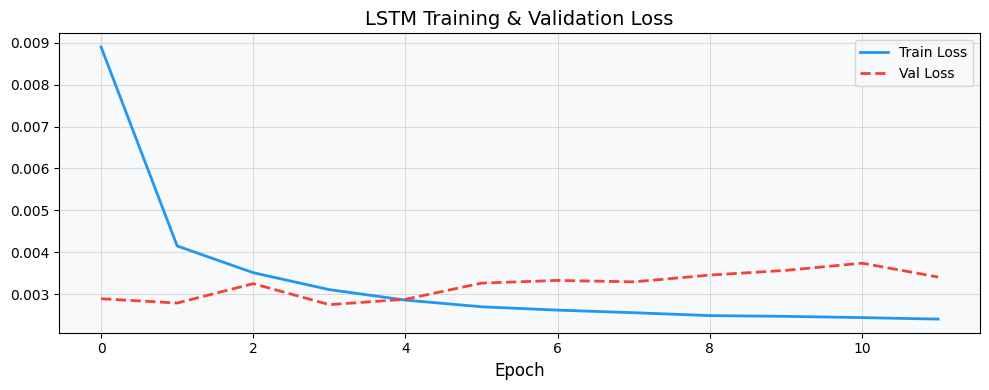

In [18]:
print("Training LSTM model...")
L = 16                                         # look-back window: 16 hours of history
X_all_sc = scaler_X.transform(df_fe[feat_cols].values)       # scaler fit on TRAIN only

def make_windows(idx):
    """Sequence for row i = the L most recent feature rows ending at row i (real time-series input)."""
    idx = idx[idx >= L - 1]
    return np.stack([X_all_sc[i - L + 1:i + 1] for i in idx]), idx

X_tr_l, idx_tr = make_windows(train_idx)
X_va_l, idx_va = make_windows(val_idx)
X_te_l, idx_te = make_windows(test_idx)
assert len(idx_va) == len(val_idx) and len(idx_te) == len(test_idx)
y_tr_l = scaler_y.transform(df_fe[TARGET].values[idx_tr].reshape(-1, 1)).ravel()

lstm_model = Sequential([Input(shape=(L, X_tr_l.shape[2])),
                         LSTM(64, return_sequences=True), Dropout(0.2),
                         LSTM(32), Dropout(0.2),
                         Dense(16, activation='relu'), Dense(1)])
lstm_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
cb = [EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=0),
      ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=0)]
history = lstm_model.fit(X_tr_l, y_tr_l, validation_data=(X_va_l, y_val_sc), epochs=40, batch_size=256,
                         callbacks=cb, verbose=0)
inv = lambda p: scaler_y.inverse_transform(np.asarray(p).reshape(-1, 1)).ravel()
record("LSTM", to_kw(inv(lstm_model.predict(X_te_l, verbose=0)), cap_test),
       to_kw(inv(lstm_model.predict(X_va_l, verbose=0)), cap_val))
print(f"LSTM trained for {len(history.history['loss'])} epochs.")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history.history['loss'], label='Train Loss', color='#2196F3', lw=2)
ax.plot(history.history['val_loss'], label='Val Loss', color='#F44336', lw=2, ls='--')
ax.set_title("LSTM Training & Validation Loss"); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.savefig('lstm_loss.png', dpi=150, bbox_inches='tight'); plt.show()

## Hyperparameter Tuning

In [20]:
param_dist = {'n_estimators': [200, 300, 400, 500], 'max_depth': [4, 5, 6, 7, 8],
              'learning_rate': [0.01, 0.03, 0.05, 0.08, 0.1], 'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
              'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0], 'reg_alpha': [0, 0.01, 0.1, 0.5, 1.0],
              'reg_lambda': [0.5, 1.0, 2.0, 5.0], 'min_child_weight': [1, 3, 5, 7]}
base_xgb = xgb.XGBRegressor(n_jobs=-1, random_state=SEED, verbosity=0, eval_metric='rmse')
rscv = RandomizedSearchCV(base_xgb, param_distributions=param_dist, n_iter=15,
                          cv=TimeSeriesSplit(n_splits=4),            # respects time order (no peeking at the future)
                          scoring='neg_root_mean_squared_error', n_jobs=-1, random_state=SEED, verbose=1)
print("Running RandomizedSearchCV (n_iter=15, TimeSeriesSplit(4))...")
rscv.fit(X_train, y_train_rel)
print("\nBest parameters:", rscv.best_params_)
print(f"Best CV RMSE (relative units): {-rscv.best_score_:.4f}")

best_xgb = rscv.best_estimator_
record("XGBoost (Tuned)", to_kw(best_xgb.predict(X_test), cap_test), to_kw(best_xgb.predict(X_val), cap_val))
base = next(r for r in results if r['Model'] == 'XGBoost'); tuned = results[-1]
print(f"\nTuning effect on test RMSE: {base['RMSE']:.4f} -> {tuned['RMSE']:.4f} kW (Δ {tuned['RMSE'] - base['RMSE']:+.4f})")

Running RandomizedSearchCV (n_iter=15, TimeSeriesSplit(4))...
Fitting 4 folds for each of 15 candidates, totalling 60 fits

Best parameters: {'subsample': 0.8, 'reg_lambda': 2.0, 'reg_alpha': 0.01, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.9}
Best CV RMSE (relative units): 0.0494
  XGBoost (Tuned)              RMSE= 0.1559  MAE= 0.0697  MAPE= 11.88%  R²=0.9787

Tuning effect on test RMSE: 0.1555 -> 0.1559 kW (Δ +0.0003)


## Model Evaluation & Comparison


                MODEL PERFORMANCE COMPARISON TABLE (kW)
                        Model   RMSE    MAE    MAPE     R2
1                    LightGBM 0.1528 0.0677 11.7535 0.9795
2                     XGBoost 0.1555 0.0694 11.9462 0.9788
3             XGBoost (Tuned) 0.1559 0.0697 11.8765 0.9787
4               Random Forest 0.1572 0.0693 12.1470 0.9783
5                        LSTM 0.1827 0.1029 15.8952 0.9707
6           Linear Regression 0.1914 0.1031 16.6771 0.9678
7  Yesterday (seasonal naive) 0.3436 0.1359 24.9679 0.8964
8                 Persistence 0.3943 0.2354 44.0324 0.8635


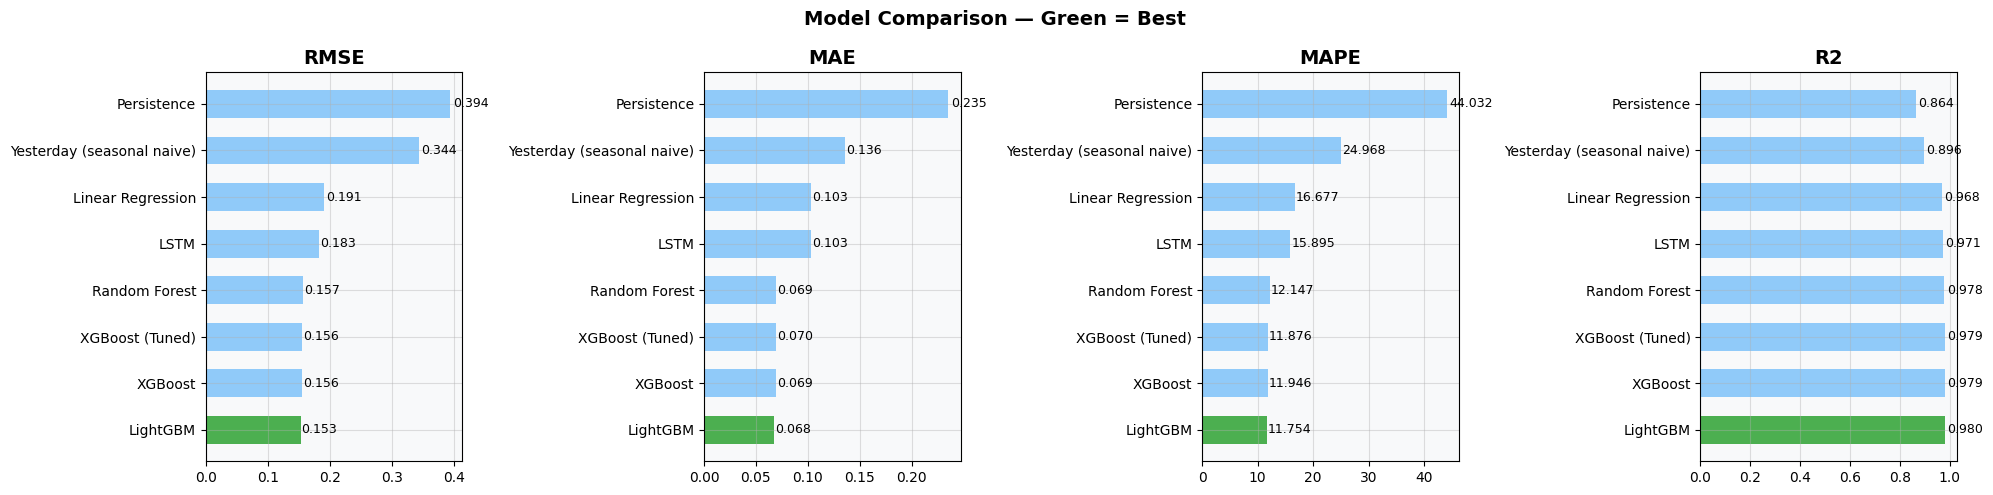

  Best model (by validation RMSE) : LightGBM
   TEST RMSE = 0.1528 kW  |  MAE = 0.0677 kW  |  R² = 0.9795
   RMSE as % of plant capacity    : 4.9%  (capacity ≈ 3.13 kW in the test period)
   Persistence baseline RMSE      : 0.3943 kW
   Improvement over persistence   : 61.3%
   Lowest TEST RMSE overall       : LightGBM (for reference only)


In [21]:
results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
results_df.index += 1
print("\n" + "=" * 70); print("                MODEL PERFORMANCE COMPARISON TABLE (kW)"); print("=" * 70)
print(results_df[['Model', 'RMSE', 'MAE', 'MAPE', 'R2']].to_string(float_format='{:.4f}'.format)); print("=" * 70)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, metric in zip(axes, ['RMSE', 'MAE', 'MAPE', 'R2']):
    vals = results_df.set_index('Model')[metric]
    best_idx = vals.idxmax() if metric == 'R2' else vals.idxmin()
    bars = ax.barh(vals.index, vals.values, color=['#4CAF50' if i == best_idx else '#90CAF9' for i in vals.index], height=0.6)
    ax.set_title(metric, fontweight='bold')
    for bar, val in zip(bars, vals.values):
        ax.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2, f'{val:.3f}', va='center', fontsize=9)
plt.suptitle("Model Comparison — Green = Best", fontsize=14, fontweight='bold'); plt.tight_layout()
plt.savefig('model_comparison_bars.png', dpi=150, bbox_inches='tight'); plt.show()

# ── Identify best model (chosen on the VALIDATION set, never on test) ─────────
baselines = ['Persistence', 'Yesterday (seasonal naive)']
ml_models = [m for m in results_df['Model'] if m not in baselines]
val_rmse = {m: np.sqrt(mean_squared_error(y_val, val_preds[m])) for m in ml_models}
best_name = min(val_rmse, key=val_rmse.get)
best_row = results_df[results_df['Model'] == best_name].iloc[0]
best_preds = predictions[best_name]
persist_rmse = results_df.loc[results_df['Model'] == 'Persistence', 'RMSE'].iloc[0]
cap_mean = float(np.mean(cap_test))

print(f"  Best model (by validation RMSE) : {best_name}")
print(f"   TEST RMSE = {best_row['RMSE']:.4f} kW  |  MAE = {best_row['MAE']:.4f} kW  |  R² = {best_row['R2']:.4f}")
print(f"   RMSE as % of plant capacity    : {best_row['RMSE'] / cap_mean * 100:.1f}%  (capacity ≈ {cap_mean:.2f} kW in the test period)")
print(f"   Persistence baseline RMSE      : {persist_rmse:.4f} kW")
print(f"   Improvement over persistence   : {(1 - best_row['RMSE'] / persist_rmse) * 100:.1f}%")
print(f"   Lowest TEST RMSE overall       : {results_df.loc[results_df['RMSE'].idxmin(), 'Model']} (for reference only)")

## Explainable AI with SHAP

Computing SHAP values...


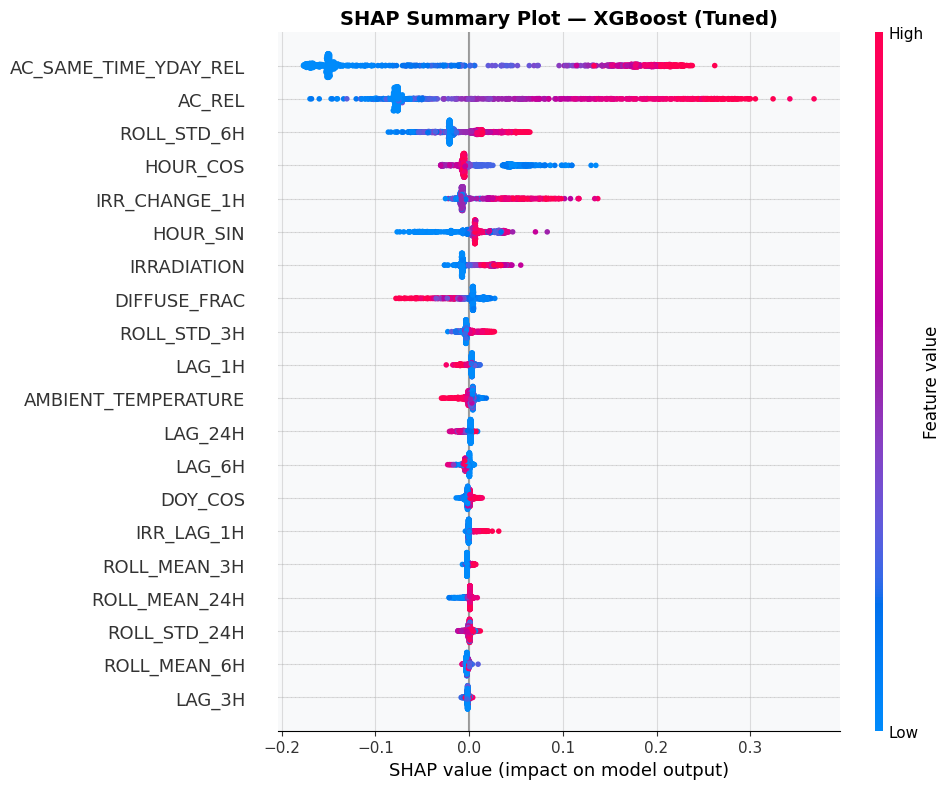

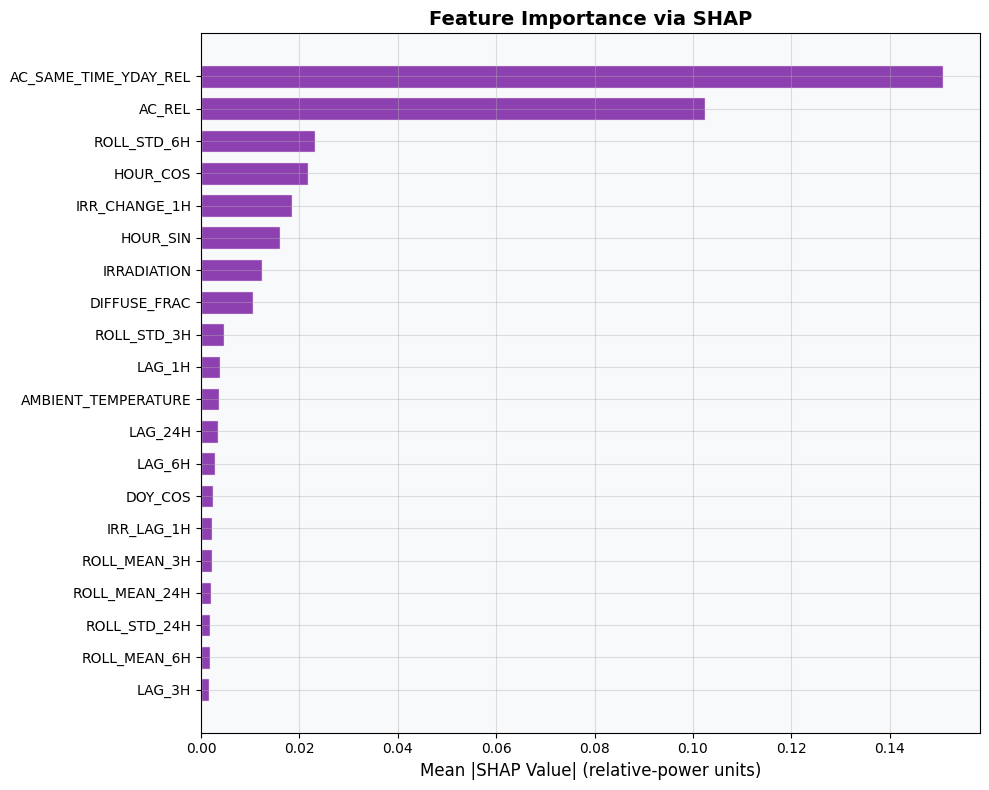


  SHAP Interpretation (read from this run):
   Top 3 most impactful features : ['AC_SAME_TIME_YDAY_REL', 'AC_REL', 'ROLL_STD_6H']
   Top weather-related features  : ['IRR_CHANGE_1H', 'IRRADIATION', 'DIFFUSE_FRAC']


In [22]:
print("Computing SHAP values...")
n_shap = min(1000, len(X_test))
idx_shap = np.random.choice(len(X_test), n_shap, replace=False)
X_shap = X_test[idx_shap]
shap_values = shap.TreeExplainer(best_xgb).shap_values(X_shap)

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_shap, feature_names=feat_cols, show=False, plot_size=None)
plt.title("SHAP Summary Plot — XGBoost (Tuned)", fontweight='bold', fontsize=14); plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight'); plt.show()

mean_shap = np.abs(shap_values).mean(axis=0)
shap_df = pd.DataFrame({'Feature': feat_cols, 'Mean |SHAP|': mean_shap}).sort_values('Mean |SHAP|', ascending=True).tail(20)
fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(shap_df['Feature'], shap_df['Mean |SHAP|'], color='#7B1FA2', edgecolor='white', height=0.7, alpha=0.85)
ax.set_xlabel("Mean |SHAP Value| (relative-power units)"); ax.set_title("Feature Importance via SHAP", fontweight='bold')
plt.tight_layout(); plt.savefig('shap_importance.png', dpi=150, bbox_inches='tight'); plt.show()

ranked = shap_df.sort_values('Mean |SHAP|', ascending=False)['Feature'].tolist()
weather = [f for f in ranked if f.startswith(('IRR', 'DIFFUSE', 'AMBIENT', 'HUMIDITY'))][:3]
print("\n  SHAP Interpretation (read from this run):")
print(f"   Top 3 most impactful features : {ranked[:3]}")
print(f"   Top weather-related features  : {weather}")

## Forecasting & Results

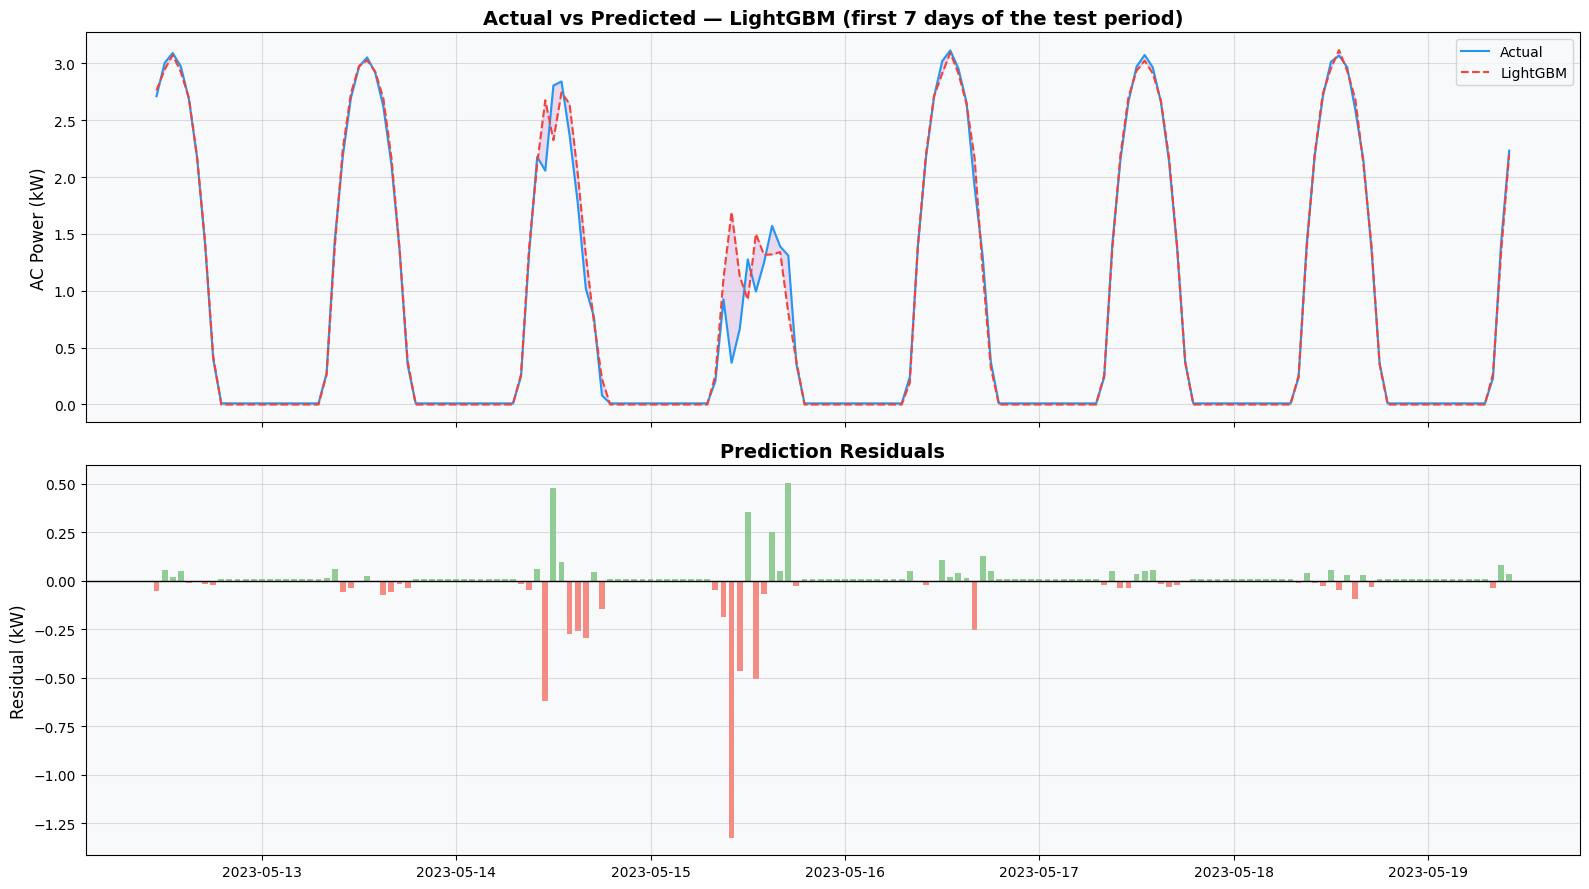

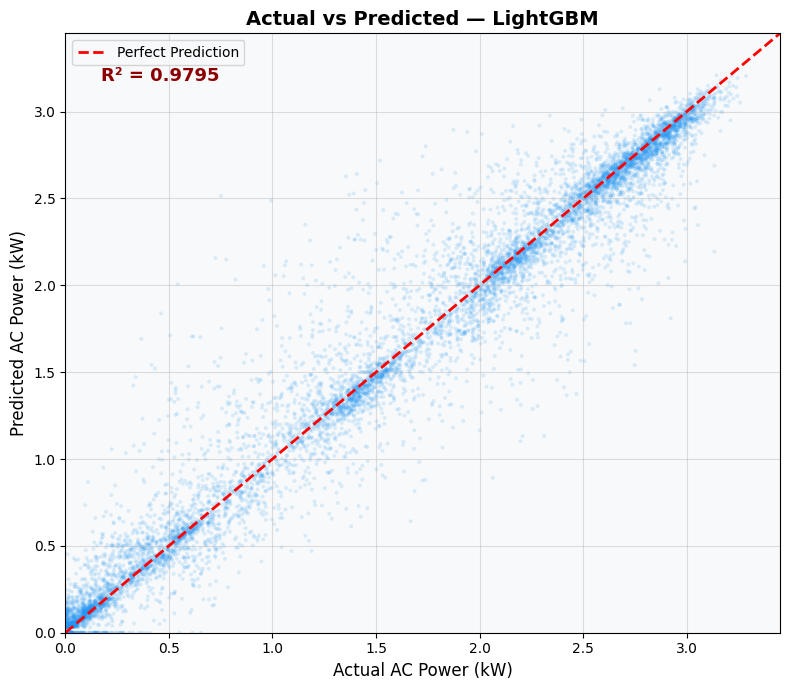

Mean error (bias): 0.0031 kW | Std: 0.1528 kW | Max over-prediction: -1.763 kW | Max under-prediction: 1.208 kW

Test-period error by month (kW):
        RMSE    MAE  Persistence_RMSE
month                                
1      0.172  0.095             0.366
2      0.166  0.085             0.378
3      0.166  0.083             0.367
4      0.129  0.062             0.409
5      0.126  0.055             0.395
6      0.132  0.057             0.379
7      0.149  0.060             0.413
8      0.092  0.036             0.409
9      0.168  0.068             0.415
10     0.154  0.071             0.397
11     0.228  0.112             0.382
12     0.178  0.085             0.380


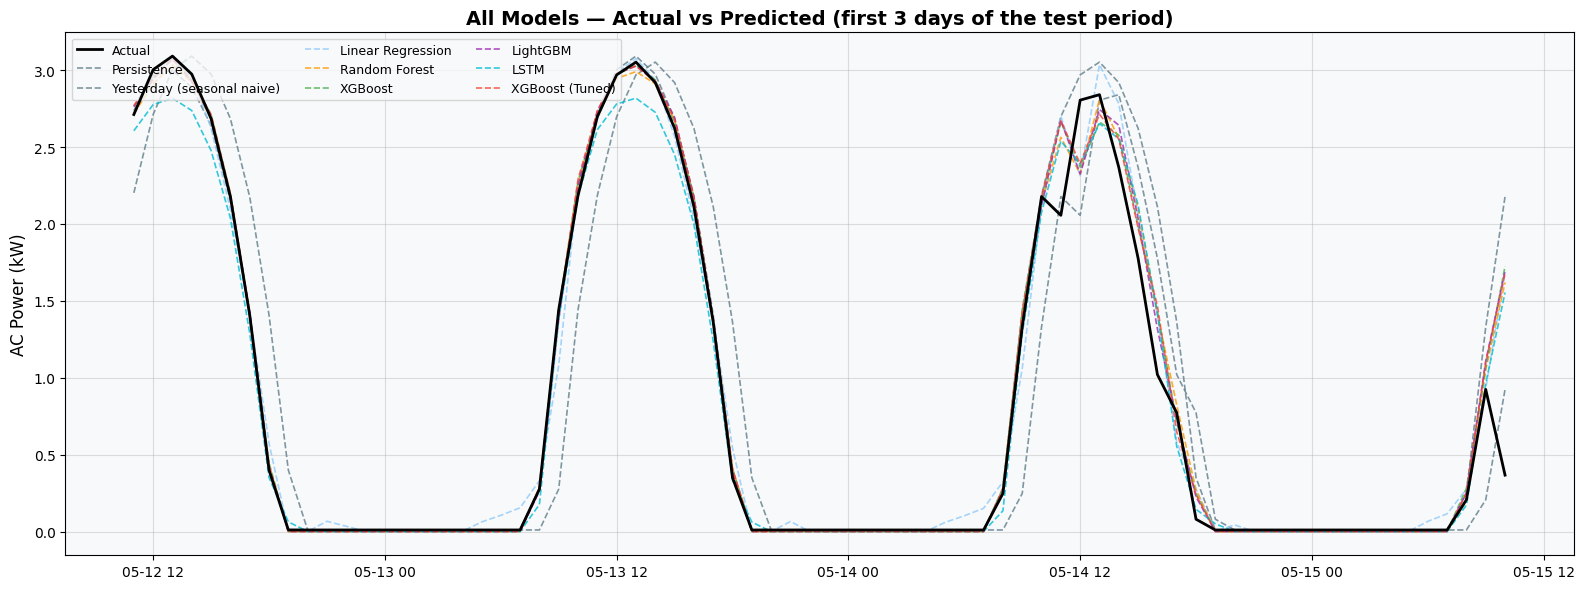

  FINAL RESULTS SUMMARY — AI-Powered Solar Generation Forecasting (DKASC site 31)
                        Model   RMSE    MAE    MAPE     R2
1                    LightGBM 0.1528 0.0677 11.7535 0.9795
2                     XGBoost 0.1555 0.0694 11.9462 0.9788
3             XGBoost (Tuned) 0.1559 0.0697 11.8765 0.9787
4               Random Forest 0.1572 0.0693 12.1470 0.9783
5                        LSTM 0.1827 0.1029 15.8952 0.9707
6           Linear Regression 0.1914 0.1031 16.6771 0.9678
7  Yesterday (seasonal naive) 0.3436 0.1359 24.9679 0.8964
8                 Persistence 0.3943 0.2354 44.0324 0.8635

 Best Model   : LightGBM
   RMSE = 0.1528 kW (4.9% of capacity)  |  R² = 0.9795


In [23]:
test_dates = test_df['TARGET_TIME'].values       # the time each forecast is FOR (issue time + 1 h)
n_plot = min(24 * 7, len(y_test))
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
axes[0].plot(test_dates[:n_plot], y_test[:n_plot], label='Actual', color='#2196F3', lw=1.5)
axes[0].plot(test_dates[:n_plot], best_preds[:n_plot], label=best_name, color='#F44336', lw=1.5, ls='--')
axes[0].fill_between(test_dates[:n_plot], y_test[:n_plot], best_preds[:n_plot], alpha=0.15, color='#9C27B0')
axes[0].set_ylabel("AC Power (kW)"); axes[0].set_title(f"Actual vs Predicted — {best_name} (first 7 days of the test period)", fontweight='bold'); axes[0].legend()
res_ = y_test[:n_plot] - best_preds[:n_plot]
axes[1].bar(test_dates[:n_plot], res_, color=np.where(res_ >= 0, '#4CAF50', '#F44336'), alpha=0.6, width=0.03)
axes[1].axhline(0, color='black', lw=1); axes[1].set_ylabel("Residual (kW)"); axes[1].set_title("Prediction Residuals", fontweight='bold')
plt.tight_layout(); plt.savefig('actual_vs_predicted.png', dpi=150, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(y_test, best_preds, alpha=0.15, s=8, color='#2196F3', edgecolors='none')
lim = max(y_test.max(), best_preds.max()) * 1.05
ax.plot([0, lim], [0, lim], 'r--', lw=2, label='Perfect Prediction'); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Actual AC Power (kW)"); ax.set_ylabel("Predicted AC Power (kW)"); ax.set_title(f"Actual vs Predicted — {best_name}", fontweight='bold')
ax.text(0.05, 0.92, f"R² = {r2_score(y_test, best_preds):.4f}", transform=ax.transAxes, fontsize=13, color='darkred', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.savefig('scatter_actual_pred.png', dpi=150, bbox_inches='tight'); plt.show()

errors = y_test - best_preds
print(f"Mean error (bias): {errors.mean():.4f} kW | Std: {errors.std():.4f} kW | "
      f"Max over-prediction: {errors.min():.3f} kW | Max under-prediction: {errors.max():.3f} kW")

# error by month of the test period (does the model hold up across seasons?)
by_month = pd.DataFrame({'month': pd.to_datetime(test_dates).month, 'err2': errors ** 2, 'ae': np.abs(errors)}).groupby('month').agg(
    RMSE=('err2', lambda x: np.sqrt(x.mean())), MAE=('ae', 'mean'))
by_month['Persistence_RMSE'] = pd.Series(
    (y_test - predictions['Persistence']) ** 2).groupby(pd.to_datetime(test_dates).month).mean().pow(0.5).values
print("\nTest-period error by month (kW):"); print(by_month.round(3).to_string())

fig, ax = plt.subplots(figsize=(16, 6))
n_ov = 24 * 3
ax.plot(test_dates[:n_ov], y_test[:n_ov], label='Actual', color='black', lw=2, zorder=10)
model_colors = {'Linear Regression': '#90CAF9', 'Random Forest': '#FF9800', 'XGBoost': '#4CAF50',
                'XGBoost (Tuned)': '#F44336', 'LightGBM': '#9C27B0', 'LSTM': '#00BCD4'}
for mname, mp in predictions.items():
    ax.plot(test_dates[:n_ov], mp[:n_ov], label=mname, lw=1.2, ls='--', alpha=0.8, color=model_colors.get(mname, '#607D8B'))
ax.set_ylabel("AC Power (kW)"); ax.set_title("All Models — Actual vs Predicted (first 3 days of the test period)", fontweight='bold')
ax.legend(loc='upper left', ncol=3, fontsize=9); plt.tight_layout()
plt.savefig('all_models_overlay.png', dpi=150, bbox_inches='tight'); plt.show()

print("=" * 70); print("  FINAL RESULTS SUMMARY — AI-Powered Solar Generation Forecasting (DKASC site 31)"); print("=" * 70)
print(results_df[['Model', 'RMSE', 'MAE', 'MAPE', 'R2']].to_string(float_format='{:.4f}'.format)); print("=" * 70)
print(f"\n Best Model   : {best_name}")
print(f"   RMSE = {best_row['RMSE']:.4f} kW ({best_row['RMSE'] / cap_mean * 100:.1f}% of capacity)  |  R² = {best_row['R2']:.4f}")

## Real-Time Forecasting (simulated replay)

The feed replays a stretch of the **held-out test period**. The feature buffer is seeded with data from *before* the feed starts,
so nothing from the future leaks in. Each forecast is issued for 1 hour ahead and scored against the actual reading that arrives 1 hour later.

In [24]:
class LiveSolarFeed:
    """Stands in for a real sensor feed (replays history one reading at a time). Swap `get_next_reading()` for a real API/MQTT call."""

    def __init__(self, history_df, start_time):
        self.history_df = history_df[history_df['DATE_TIME'] >= start_time].reset_index(drop=True)
        self.cursor = 0

    def has_next(self):
        return self.cursor < len(self.history_df)

    def get_next_reading(self):
        if not self.has_next():
            raise StopIteration("Live feed exhausted.")
        row = self.history_df.iloc[self.cursor]
        self.cursor += 1
        return row.to_dict()

N_STEPS = 240          # 10 days of hourly readings
LOOK = 24 * S
# first clean stretch (no filled-in gaps) inside the test period, so the replay is a genuine measurement series
gap_arr = df['LONG_GAP'].values.astype(int)
t0 = test_df['DATE_TIME'].iloc[0]
start_pos = next(i for i in np.where(df['DATE_TIME'].values >= np.datetime64(t0))[0]
                 if i >= 200 and gap_arr[i - 200:i + N_STEPS + H + 1].sum() == 0)
live_feed = LiveSolarFeed(df.iloc[:start_pos + N_STEPS + H + 1], start_time=df['DATE_TIME'].iloc[start_pos])
print(f"Live feed ready - streaming {len(live_feed.history_df)} readings starting {live_feed.history_df['DATE_TIME'].iloc[0]}")

class RollingFeatureBuilder:
    """Keeps a window of recent readings and turns the latest one into a feature row, using the SAME make_features() as training."""

    def __init__(self, seed_df, feat_cols, buffer_size=200):
        self.buffer = seed_df.tail(buffer_size).copy().reset_index(drop=True)
        self.feat_cols, self.buffer_size = feat_cols, buffer_size

    def add_reading(self, reading: dict):
        self.buffer = pd.concat([self.buffer, pd.DataFrame([reading])], ignore_index=True).tail(self.buffer_size).reset_index(drop=True)
        latest = make_features(self.buffer).iloc[[-1]][self.feat_cols]
        if latest.isna().values.any():
            raise ValueError("Not enough history in the buffer to build all features.")
        return latest.values

feature_builder = RollingFeatureBuilder(df[df['DATE_TIME'] < live_feed.history_df['DATE_TIME'].iloc[0]], feat_cols)
print(f"Buffer seeded with {len(feature_builder.buffer)} readings, all earlier than the first streamed reading.")

def run_live_forecast(feed, builder, model, n_steps=N_STEPS):
    """Issue a 1-hour-ahead forecast at every reading; score it when the actual for that future time arrives."""
    log, pending = [], {}
    step_td = pd.Timedelta(minutes=STEP_MIN * H)
    for _ in range(n_steps):
        if not feed.has_next():
            break
        reading = feed.get_next_reading()
        t = pd.Timestamp(reading['DATE_TIME'])
        if t in pending:
            fc, pers = pending.pop(t)
            log.append({'DATE_TIME': t, 'ACTUAL': reading['AC_POWER'], 'FORECAST': fc, 'PERSISTENCE': pers,
                        'ERROR': reading['AC_POWER'] - fc})
        feat_row = builder.add_reading(reading)
        fc = to_kw(model.predict(feat_row), np.array([reading['CAP']]))[0]
        pending[t + step_td] = (fc, reading['AC_POWER'])
    return pd.DataFrame(log)

print("Streaming readings through the tuned XGBoost model...")
live_log = run_live_forecast(live_feed, feature_builder, best_xgb)
live_rmse = np.sqrt(mean_squared_error(live_log['ACTUAL'], live_log['FORECAST']))
pers_rmse = np.sqrt(mean_squared_error(live_log['ACTUAL'], live_log['PERSISTENCE']))
print(f"\nScored {len(live_log)} one-hour-ahead forecasts.")
print(f"Live RMSE        : {live_rmse:.4f} kW")
print(f"Persistence RMSE : {pers_rmse:.4f} kW   (baseline: 'power in 1 h = power now')")
print(live_log.tail(5).to_string(index=False))

Live feed ready - streaming 242 readings starting 2023-05-12 10:00:00
Buffer seeded with 200 readings, all earlier than the first streamed reading.
Streaming readings through the tuned XGBoost model...

Scored 239 one-hour-ahead forecasts.
Live RMSE        : 0.1242 kW
Persistence RMSE : 0.4217 kW   (baseline: 'power in 1 h = power now')
          DATE_TIME   ACTUAL  FORECAST  PERSISTENCE    ERROR
2023-05-22 05:00:00 0.010000  0.000000     0.010000 0.010000
2023-05-22 06:00:00 0.009994  0.000000     0.010000 0.009994
2023-05-22 07:00:00 0.009944  0.000000     0.009994 0.009944
2023-05-22 08:00:00 0.214411  0.181965     0.009944 0.032446
2023-05-22 09:00:00 1.400222  1.343329     0.214411 0.056894


### Live Monitoring View

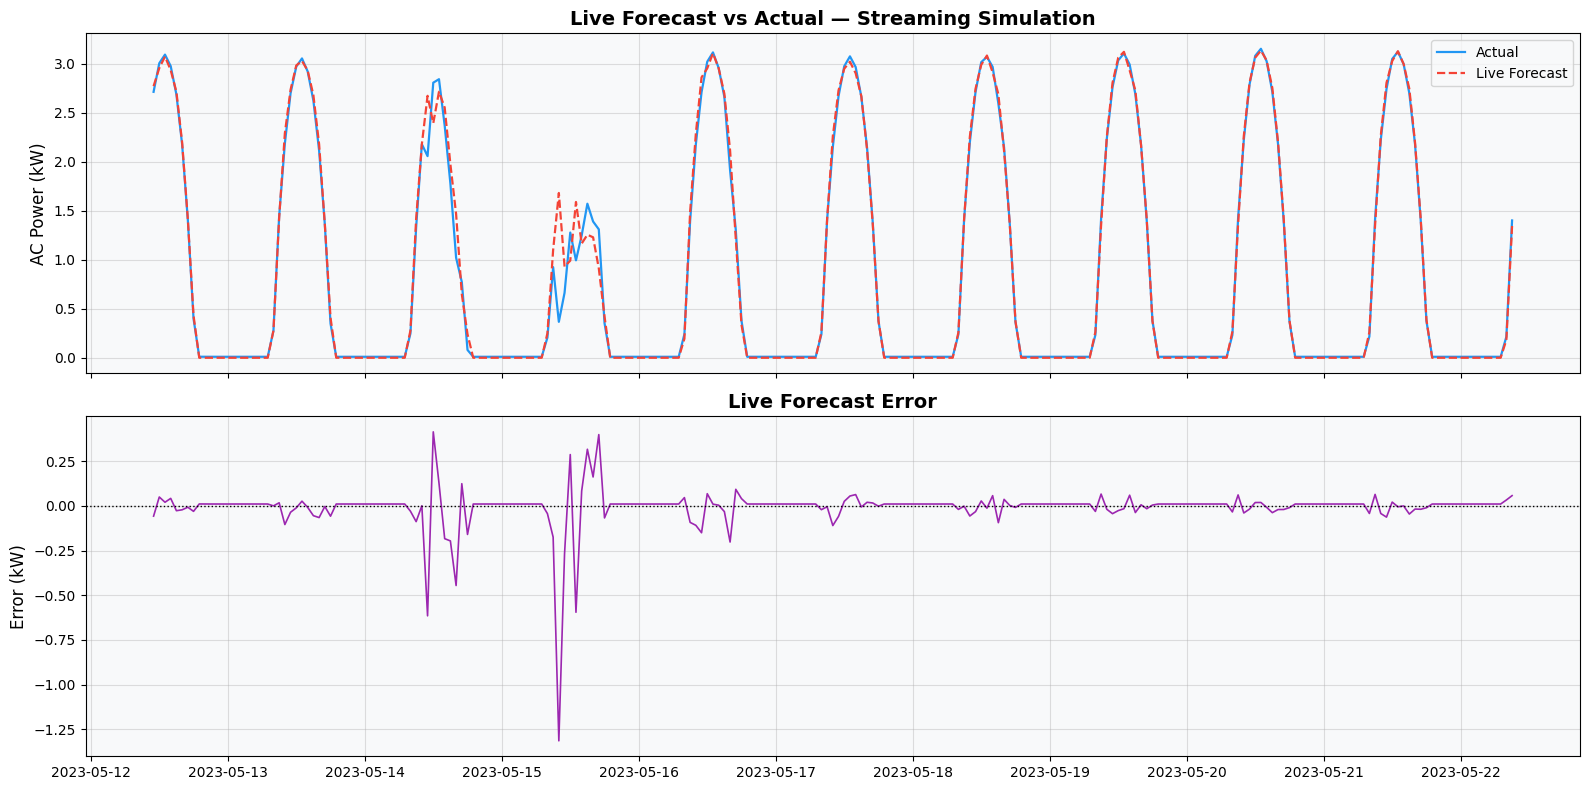

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
axes[0].plot(live_log['DATE_TIME'], live_log['ACTUAL'], label='Actual', color='#2196F3', lw=1.6)
axes[0].plot(live_log['DATE_TIME'], live_log['FORECAST'], label='Live Forecast', color='#F44336', lw=1.6, ls='--')
axes[0].set_ylabel("AC Power (kW)"); axes[0].set_title("Live Forecast vs Actual — Streaming Simulation", fontweight='bold'); axes[0].legend()
axes[1].plot(live_log['DATE_TIME'], live_log['ERROR'], color='#9C27B0', lw=1.2); axes[1].axhline(0, color='black', lw=1, ls=':')
axes[1].set_ylabel("Error (kW)"); axes[1].set_title("Live Forecast Error", fontweight='bold')
plt.tight_layout(); plt.savefig('live_forecast.png', dpi=150, bbox_inches='tight'); plt.show()

### On-Demand Forecast Function

In [26]:
def forecast_next(reading: dict, builder=feature_builder, model=best_xgb):
    """Take the latest reading (dict with the same keys as a row of `df`, including CAP and the CURRENT AC_POWER)
    and return the AC power forecast in kW for 1 hour later."""
    feat_row = builder.add_reading(reading)
    return round(float(to_kw(model.predict(feat_row), np.array([reading['CAP']]))[0]), 4)

if live_feed.has_next():
    sample = live_feed.get_next_reading()
    t_future = pd.Timestamp(sample['DATE_TIME']) + pd.Timedelta(minutes=STEP_MIN * H)
    actual = df.loc[df['DATE_TIME'] == t_future, 'AC_POWER']
    print(f"Reading time     : {sample['DATE_TIME']}")
    print(f"Forecast for     : {t_future}")
    print(f"Forecasted AC kW : {forecast_next(sample)}")
    if len(actual):
        print(f"Actual AC kW     : {actual.iloc[0]:.4f}  (known only because this is a replay)")

Reading time     : 2023-05-22 10:00:00
Forecast for     : 2023-05-22 11:00:00
Forecasted AC kW : 2.7523
Actual AC kW     : 2.7133  (known only because this is a replay)


## Prediction Intervals (Quantile LightGBM)

A point forecast says "0.8 kW"; a grid operator also needs to know *how sure* that is. Here LightGBM is trained with the **quantile (pinball) loss** at the 5th and 95th percentiles, giving a nominal **90% prediction interval** around the median forecast.

Because quantile models are usually slightly over- or under-confident, the interval is then **calibrated on the validation set only** (conformalized quantile regression, CQR). The test set is used just once, to report honest coverage.

Coverage is reported for **daytime hours only** (target above 5% of peak). At night the power is exactly 0 and trivially "covered", which would inflate the number, just as it does for R².

Training quantile models (5%, 50%, 95%)...

Calibration shift q_hat = 0.0007 kW (positive = raw band was too narrow)
                      Interval  Coverage (daytime)  Coverage (all hours)  Mean width daytime (kW)  Width % of capacity
    Raw quantile (nominal 90%)               83.66                 69.35                     0.57                18.20
Calibrated on validation (CQR)               83.91                 69.47                     0.57                18.25


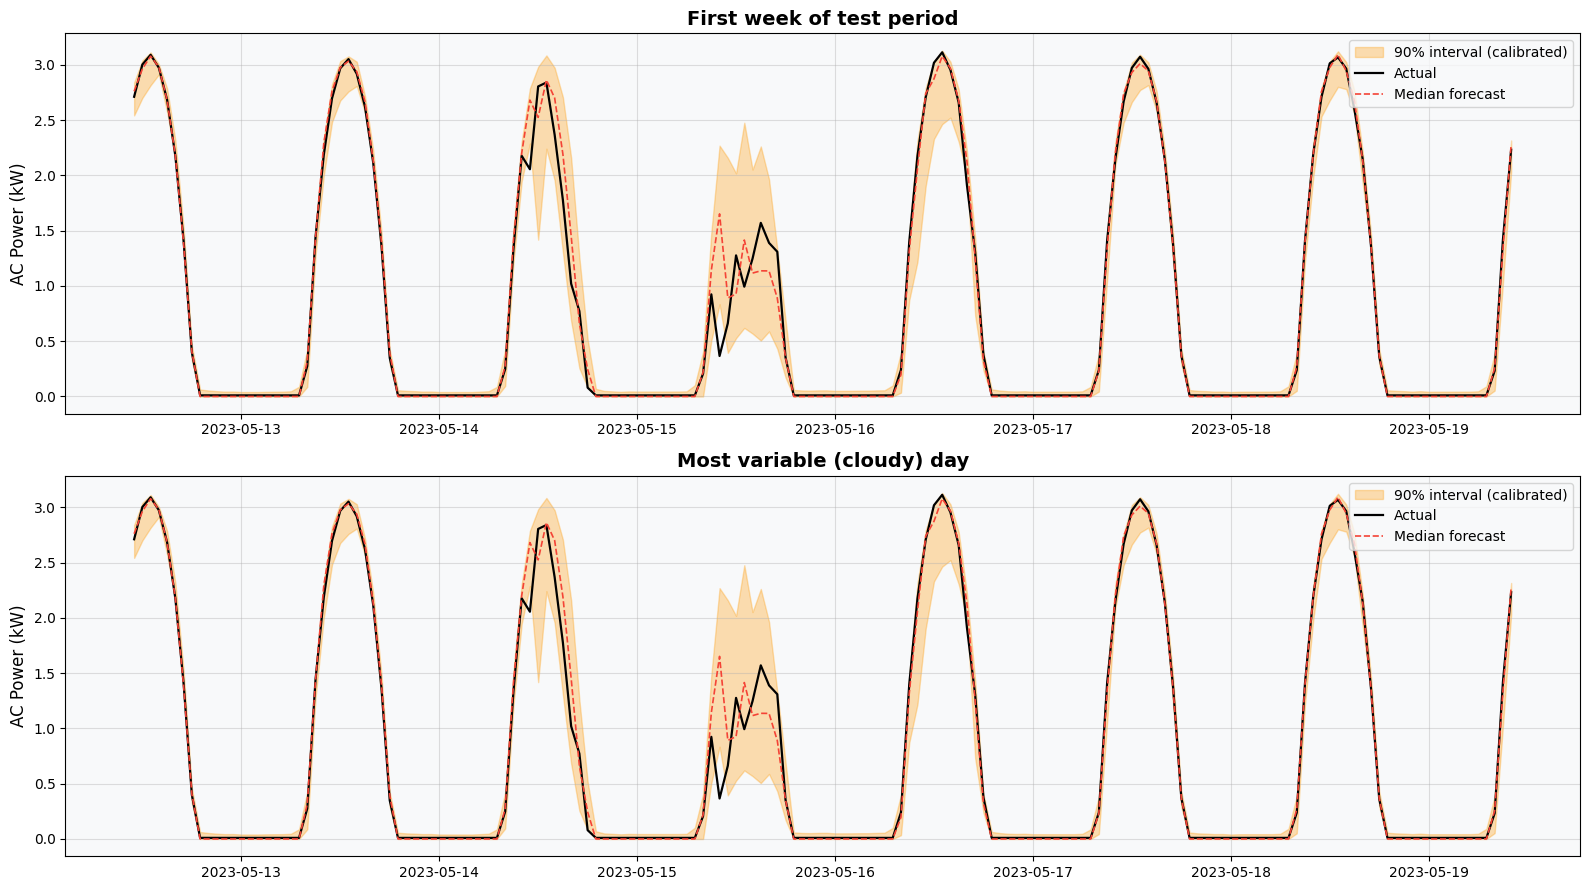

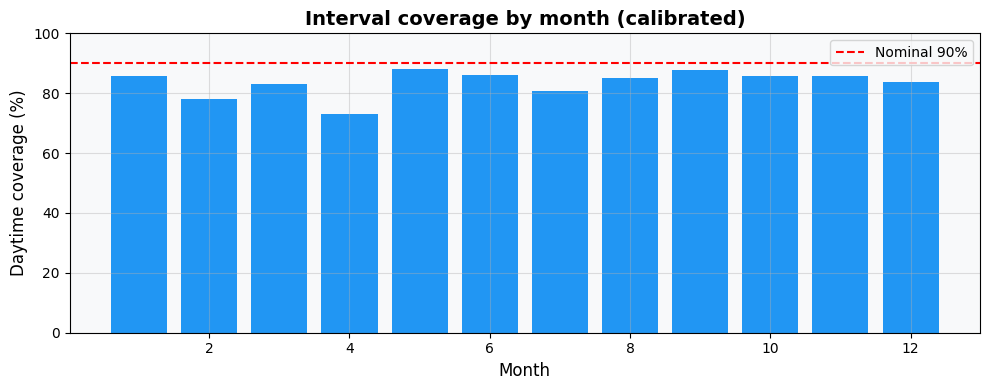


Prediction-interval summary: the calibrated 90% band covered 83.9% of daytime test hours, with an average width of 0.572 kW (18.2% of capacity).


In [27]:
# ── Prediction intervals: quantile LightGBM + conformal calibration (CQR) ───────────────────────
ALPHA_LO, ALPHA_HI = 0.05, 0.95          # nominal 90% interval
NOMINAL = ALPHA_HI - ALPHA_LO

def fit_quantile(alpha):
    m = lgb.LGBMRegressor(objective='quantile', alpha=alpha, n_estimators=1000, learning_rate=0.05, num_leaves=63,
                          max_depth=7, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                          n_jobs=-1, random_state=SEED, verbose=-1)
    m.fit(X_train, y_train_rel, eval_set=[(X_val, y_val_rel)],
          callbacks=[lgb.early_stopping(30, verbose=False), lgb.log_evaluation(-1)])
    return m

print("Training quantile models (5%, 50%, 95%)...")
q_models = {a: fit_quantile(a) for a in (ALPHA_LO, 0.5, ALPHA_HI)}

def predict_band(X, cap):
    lo = to_kw(q_models[ALPHA_LO].predict(X), cap)
    md = to_kw(q_models[0.5].predict(X), cap)
    hi = to_kw(q_models[ALPHA_HI].predict(X), cap)
    lo = np.minimum(lo, md); hi = np.maximum(hi, md)       # quantile crossing fix: lo <= median <= hi
    return lo, md, hi

lo_val, md_val, hi_val = predict_band(X_val, cap_val)
lo_te, md_te, hi_te = predict_band(X_test, cap_test)

day_thr = 0.05 * y_train.max()
day_val, day_te = y_val > day_thr, y_test > day_thr

# Conformal calibration on VALIDATION daytime rows: widen (or tighten) both ends by q_hat
scores = np.maximum(lo_val - y_val, y_val - hi_val)[day_val]
n_cal = len(scores)
q_hat = np.quantile(scores, min(1.0, np.ceil((n_cal + 1) * NOMINAL) / n_cal), method='higher')
active_te = md_te > 0                                       # only adjust when the model expects sun
lo_cal = np.where(active_te, np.maximum(lo_te - q_hat, 0), lo_te)
hi_cal = np.where(active_te, hi_te + q_hat, hi_te)

def band_stats(name, lo, hi):
    inside = (y_test >= lo) & (y_test <= hi)
    return {'Interval': name,
            'Coverage (daytime)': inside[day_te].mean() * 100,
            'Coverage (all hours)': inside.mean() * 100,
            'Mean width daytime (kW)': (hi - lo)[day_te].mean(),
            'Width % of capacity': (hi - lo)[day_te].mean() / cap_mean * 100}

pi_table = pd.DataFrame([band_stats('Raw quantile (nominal 90%)', lo_te, hi_te),
                         band_stats('Calibrated on validation (CQR)', lo_cal, hi_cal)])
print(f"\nCalibration shift q_hat = {q_hat:.4f} kW (positive = raw band was too narrow)")
print(pi_table.round(2).to_string(index=False))

# ── Plot: one clear week and one cloudy week ────────────────────────────────────────────────────
t_dates = pd.to_datetime(test_dates)
daily_var = pd.Series(y_test).groupby(t_dates.date).std()
cloudy_day = pd.Timestamp(daily_var.idxmax())
starts = {'First week of test period': 0,
          'Most variable (cloudy) day': int(np.searchsorted(t_dates, cloudy_day - pd.Timedelta(days=3)))}
fig, axes = plt.subplots(2, 1, figsize=(16, 9))
for ax, (title, s0) in zip(axes, starts.items()):
    sl = slice(s0, min(s0 + 24 * 7, len(y_test)))
    ax.fill_between(t_dates[sl], lo_cal[sl], hi_cal[sl], color='#FF9800', alpha=0.3, label='90% interval (calibrated)')
    ax.plot(t_dates[sl], y_test[sl], color='black', lw=1.6, label='Actual')
    ax.plot(t_dates[sl], md_te[sl], color='#F44336', lw=1.2, ls='--', label='Median forecast')
    ax.set_ylabel('AC Power (kW)'); ax.set_title(title, fontweight='bold'); ax.legend(loc='upper right')
plt.tight_layout(); plt.savefig('prediction_intervals.png', dpi=150, bbox_inches='tight'); plt.show()

# ── Is the coverage steady across months? ───────────────────────────────────────────────────────
inside_cal = (y_test >= lo_cal) & (y_test <= hi_cal)
cov_month = pd.Series(inside_cal[day_te]).groupby(t_dates.month[day_te]).mean() * 100
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(cov_month.index, cov_month.values, color='#2196F3')
ax.axhline(NOMINAL * 100, color='red', ls='--', label='Nominal 90%')
ax.set_xlabel('Month'); ax.set_ylabel('Daytime coverage (%)'); ax.set_title('Interval coverage by month (calibrated)', fontweight='bold')
ax.set_ylim(0, 100); ax.legend(); plt.tight_layout(); plt.savefig('interval_coverage_by_month.png', dpi=150, bbox_inches='tight'); plt.show()

cal_row = pi_table.iloc[1]
print(f"\nPrediction-interval summary: the calibrated 90% band covered {cal_row['Coverage (daytime)']:.1f}% of daytime test hours, "
      f"with an average width of {cal_row['Mean width daytime (kW)']:.3f} kW ({cal_row['Width % of capacity']:.1f}% of capacity).")

## Walk-Forward (Expanding-Window) Cross-Validation

A single 60/20/20 split gives one number, which could be lucky or unlucky depending on the weather in that test window. Here the data after the first 40% is cut into **5 consecutive test blocks**. For each block, LightGBM is re-trained on **everything before it** (with an H-step gap so targets never overlap) and scored on that block. Training data never comes from the future of the block being tested.

The model uses fixed hyper-parameters (no early stopping on the test block), so each fold is an honest out-of-sample score. Persistence is scored on the same rows for comparison.

  fold 1/5 done
  fold 2/5 done
  fold 3/5 done
  fold 4/5 done
  fold 5/5 done

 Fold              Test period  Train rows  Test rows  LightGBM RMSE (kW)  MAE (kW)  RMSE % of capacity  Persistence RMSE (kW)  Gain vs persistence %
    1 2018-09-23 -> 2020-02-12       39337      11854               0.180     0.084               4.438                  0.507                 64.529
    2 2020-02-12 -> 2021-07-04       51191      11668               0.158     0.065               4.307                  0.459                 65.675
    3 2021-07-04 -> 2022-11-24       62859      11522               0.157     0.067               4.608                  0.433                 63.663
    4 2022-11-24 -> 2024-04-14       74381      10361               0.160     0.070               4.880                  0.400                 60.069
    5 2024-04-14 -> 2025-09-03       84742      10343               0.153     0.068               4.996                  0.395                 61.343

Mean and std acros

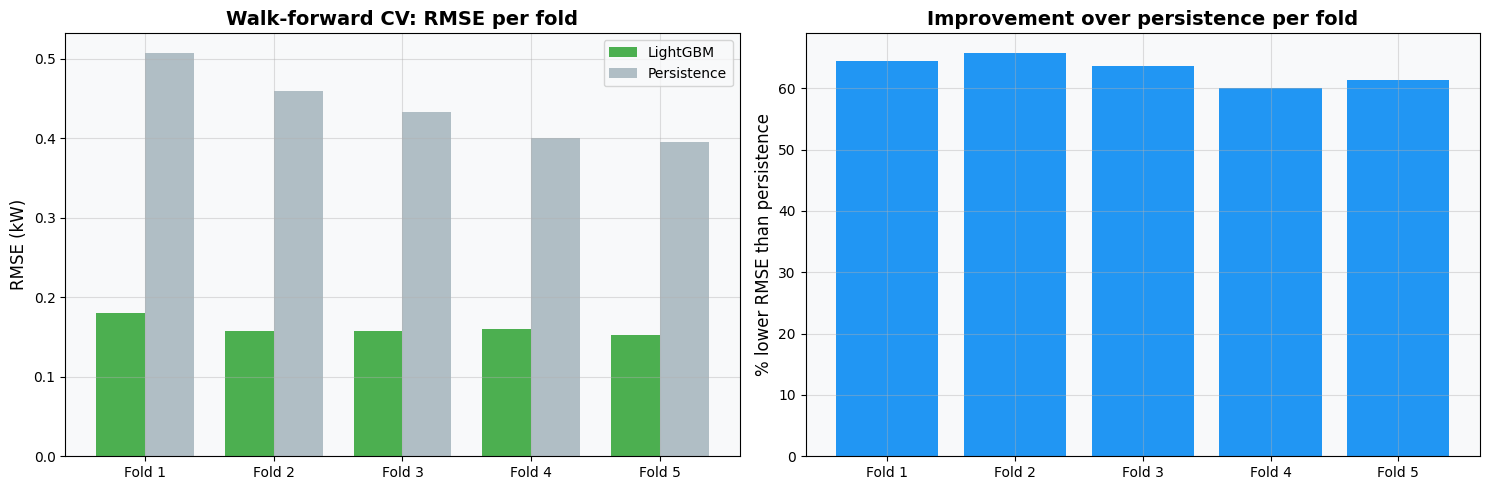


Walk-forward CV: LightGBM RMSE = 0.162 ± 0.011 kW (4.6% of capacity), 63% ± 2% better than persistence across 5 folds.


In [28]:
# ── Walk-forward cross-validation ───────────────────────────────────────────────────────────────
N_FOLDS = 5
start0 = int(len(df_fe) * 0.40)                          # first test block starts after 40% of the data
edges = np.linspace(start0, len(df_fe), N_FOLDS + 1, dtype=int)
good = ~bad_row
cv_rows = []

for k in range(N_FOLDS):
    te_lo, te_hi = edges[k], edges[k + 1]
    tr = np.arange(0, te_lo - GAP); tr = tr[good[tr]]
    te = np.arange(te_lo, te_hi);   te = te[good[te]]
    Xtr, ytr = df_fe.iloc[tr][feat_cols].values, df_fe.iloc[tr][TARGET].values
    Xte, yte = df_fe.iloc[te][feat_cols].values, df_fe.iloc[te]['TARGET_KW'].values
    cap_te = df_fe.iloc[te]['CAP'].values

    m = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, max_depth=7, num_leaves=63, subsample=0.8,
                          subsample_freq=1, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
                          n_jobs=-1, random_state=SEED, verbose=-1)
    m.fit(Xtr, ytr)
    p = to_kw(m.predict(Xte), cap_te)
    p0 = df_fe.iloc[te]['AC_NOW'].values                  # persistence

    rmse, rmse0 = np.sqrt(mean_squared_error(yte, p)), np.sqrt(mean_squared_error(yte, p0))
    cv_rows.append({'Fold': k + 1,
                    'Test period': f"{df_fe.iloc[te]['TARGET_TIME'].min().date()} -> {df_fe.iloc[te]['TARGET_TIME'].max().date()}",
                    'Train rows': len(tr), 'Test rows': len(te),
                    'LightGBM RMSE (kW)': rmse, 'MAE (kW)': mean_absolute_error(yte, p),
                    'RMSE % of capacity': rmse / cap_te.mean() * 100,
                    'Persistence RMSE (kW)': rmse0, 'Gain vs persistence %': (1 - rmse / rmse0) * 100})
    print(f"  fold {k + 1}/{N_FOLDS} done")

cv_df = pd.DataFrame(cv_rows)
print("\n" + cv_df.to_string(index=False, float_format='{:.3f}'.format))
summ = cv_df[['LightGBM RMSE (kW)', 'RMSE % of capacity', 'Persistence RMSE (kW)', 'Gain vs persistence %']].agg(['mean', 'std'])
print("\nMean and std across folds:"); print(summ.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
w = 0.38; x = np.arange(N_FOLDS)
ax[0].bar(x - w / 2, cv_df['LightGBM RMSE (kW)'], w, label='LightGBM', color='#4CAF50')
ax[0].bar(x + w / 2, cv_df['Persistence RMSE (kW)'], w, label='Persistence', color='#B0BEC5')
ax[0].set_xticks(x); ax[0].set_xticklabels([f"Fold {i}" for i in cv_df['Fold']]); ax[0].set_ylabel('RMSE (kW)')
ax[0].set_title('Walk-forward CV: RMSE per fold', fontweight='bold'); ax[0].legend()
ax[1].bar(x, cv_df['Gain vs persistence %'], color='#2196F3')
ax[1].set_xticks(x); ax[1].set_xticklabels([f"Fold {i}" for i in cv_df['Fold']]); ax[1].set_ylabel('% lower RMSE than persistence')
ax[1].set_title('Improvement over persistence per fold', fontweight='bold')
plt.tight_layout(); plt.savefig('walk_forward_cv.png', dpi=150, bbox_inches='tight'); plt.show()

print(f"\nWalk-forward CV: LightGBM RMSE = {summ.loc['mean','LightGBM RMSE (kW)']:.3f} ± {summ.loc['std','LightGBM RMSE (kW)']:.3f} kW "
      f"({summ.loc['mean','RMSE % of capacity']:.1f}% of capacity), "
      f"{summ.loc['mean','Gain vs persistence %']:.0f}% ± {summ.loc['std','Gain vs persistence %']:.0f}% better than persistence across {N_FOLDS} folds.")

In [29]:
# ── Export the replay data for the dashboard ────────────────────────────────
export = pd.DataFrame({
    'time':        pd.to_datetime(test_dates),
    'actual_kw':   y_test,
    'forecast_kw': predictions['LightGBM'],
    'persist_kw':  predictions['Persistence'],
    'lo_kw':       lo_cal,
    'hi_kw':       hi_cal,
    'capacity_kw': cap_test,
})
export.to_csv('dashboard_data.csv', index=False)
print(export.shape)
print("RMSE LightGBM   :", np.sqrt(mean_squared_error(export.actual_kw, export.forecast_kw)))
print("RMSE persistence:", np.sqrt(mean_squared_error(export.actual_kw, export.persist_kw)))

from google.colab import files
files.download('dashboard_data.csv')

(16963, 7)
RMSE LightGBM   : 0.15278288992053135
RMSE persistence: 0.3942916247298777


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>